# Анализ лояльности пользователей Яндекс Афиши

## Цель и задачи

**Цель:** Провести исследовательский анализ данных, чтобы понять, какие пользователи с большей вероятностью возвращаются на платформу "Яндекс Афиша" и делают заказы повторно. Это позволит быстро выявлять перспективных клиентов и предлагать им персонализированные условия, точнее настраивать рекламу и оптимизировать бюджеты, а в итоге повысить удержание клиентов.

**Задачи:**

1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.
4. Исследовать признаки, влияющие на возврат пользователей.
5. Написать общие выводы и рекомендации.


## Данные и их описание

Выгрузка из базы данных SQL позволила собрать следующие данные:
- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (использованы данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (использованы данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.


## Структура проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Создание профиля пользователя.
4. Исследовательский анализ данных.
5. Общие выводы и рекомендации.

## 1. Загрузка данных и знакомство с ними

Импортируем необходимые библиотеки:

In [1]:
import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from phik import phik_matrix

from dotenv import load_dotenv
import os

Загрузка данных:

In [2]:
load_dotenv(dotenv_path='.env')

db_config = {'user': os.getenv('USER'),   # имя пользователя
             'pwd': os.getenv('PWD'),     # пароль
             'host': os.getenv('HOST'),   # хост
             'port': os.getenv('PORT'),   # порт подключения
             'db': os.getenv('DB')        # название базы данных
            }

In [3]:
connection_string = 'postgresql+psycopg2://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

In [4]:
engine = create_engine(connection_string)

In [5]:
query = '''
SELECT user_id,
	   device_type_canonical,
	   order_id,
	   created_dt_msk AS order_dt,
	   created_ts_msk AS order_ts,
	   currency_code,
	   revenue,
	   tickets_count,
	   created_dt_msk::date - LAG(created_dt_msk) OVER (PARTITION BY user_id ORDER BY created_dt_msk)::date AS days_since_prev,
	   event_id,
	   event_name_code AS event_name,
	   event_type_main,
	   service_name,
	   region_name,
	   city_name
FROM afisha.purchases AS p
INNER JOIN afisha.events USING (event_id)
INNER JOIN afisha.city USING (city_id)
INNER JOIN afisha.regions USING (region_id)
WHERE device_type_canonical IN ('mobile', 'desktop') AND event_type_main != 'фильм'
ORDER BY user_id;
'''

In [6]:
df = pd.read_sql_query(query, con=engine)

Выводим информацию о датафрейме:

In [7]:
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  str           
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  str           
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  str           
 12  service_name           290611 non-null  str           


Датасет содержит **15 столбцов** и **290611 строк**, в которых представлена информация о заказах на платформе "Яндекс Афиша".

После первичного анализа данных можно сделать следующие выводы:

- Представленные данные хранятся в следующих типах данных: `datetime64[us](2)`, `float64(2)`, `int64(3)`, `str(8)`.

Значения в столбцах `user_id`, `device_type_canonical`, `currency_code`, `event_name`, `event_type_main`, `service_name`, `region_name`, `city_name` представлены текстом.

Тип в столбцах `order_id`, `tickets_count`, `event_id` — `int64`, однако можно проверить максимальные значения в этих столбцах и если они не выходят за границу `int32`, то понизить до соответствующей размерности.

Дата создания заказа (`order_dt`), а также дата и время создания заказа (`order_ts`) имеют тип `datetime64[us]`.

Столбец с выручкой (`revenue`) имеет тип `float64`, лучше так и оставить.

Столбец `days_since_prev` также имеет тип `float64`, однако его размерность можно оптимизировать (`float32`).

- Пропуски содержатся только в столбце `days_since_prev`. Это означает, что **21933 (7.6%)** пользователей совершили лишь одну покупку на платформе.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.

## 2. Предобработка данных

### 2.1. Приводим выручку к единой валюте — российскому рублю

In [9]:
df['currency_code'].unique()

<StringArray>
['rub', 'kzt']
Length: 2, dtype: str

In [10]:
currency_df = pd.read_csv('data/final_tickets_tenge_df.csv')

In [11]:
currency_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [12]:
currency_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    str    
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    str    
dtypes: float64(1), int64(1), str(2)
memory usage: 11.3 KB


Приводим строковую дату в датафрейме `currency_df` к типу `datetime64`:

In [13]:
currency_df['data'] = pd.to_datetime(currency_df['data'])

Создаем словарь с курсами и проходим в цикле по каждой строке датафрейма:

In [14]:
rates = dict(zip(currency_df['data'], currency_df['curs']))

revenue_rub = []

for i in range(df.shape[0]):
    if df.loc[i, 'currency_code'] == 'kzt':
        revenue_rub.append(
            df.loc[i, 'revenue']
            * rates[df.loc[i, 'order_dt']]
            / 100)
    else:
        revenue_rub.append(df.loc[i, 'revenue'])

df['revenue_rub'] = revenue_rub

### 2.2. Пропущенные значения, оптимизация типов данных, значения в ключевых столбцах

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  str           
 1   device_type_canonical  290611 non-null  str           
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[us]
 4   order_ts               290611 non-null  datetime64[us]
 5   currency_code          290611 non-null  str           
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  str           
 11  event_type_main        290611 non-null  str           
 12  service_name           290611 non-null  str           


Как уже было отмечено ранее, **пропуски** содержатся **только в столбце `days_since_prev`**.

Преобразуем типы данных в столбцах `order_id`, `tickets_count`, `event_id`.

In [16]:
display(df[['order_id', 'tickets_count', 'event_id']].agg(['min', 'max']))

,order_id,tickets_count,event_id
min,1,1,4436
max,8653108,57,592325


In [17]:
for col in ['order_id', 'tickets_count', 'event_id']:
    df[col] = df[col].astype('int32')

df[['order_id', 'tickets_count', 'event_id']].dtypes

order_id         int32
tickets_count    int32
event_id         int32
dtype: object

Оптимизируем тип в столбце `days_since_prev`:

In [18]:
df['days_since_prev'] = df['days_since_prev'].astype('float32')

Изучим номинальные данные.

В нашем датафрейме это: `device_type_canonical`, `currency_code`, `event_type_main`, `service_name`, `region_name`, `city_name`.

In [19]:
df['device_type_canonical'].value_counts(dropna=False)

device_type_canonical
mobile     232490
desktop     58121
Name: count, dtype: int64

In [20]:
df['currency_code'].value_counts(dropna=False)

currency_code
rub    285542
kzt      5069
Name: count, dtype: int64

In [21]:
df['event_type_main'].value_counts(dropna=False)

event_type_main
концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: count, dtype: int64

In [22]:
df['service_name'].value_counts(dropna=False)

service_name
Билеты без проблем        63519
Лови билет!               41124
Билеты в руки             40343
Мой билет                 34839
Облачко                   26642
Лучшие билеты             17774
Весь в билетах            16849
Прачечная                 10273
Край билетов               6207
Тебе билет!                5228
Яблоко                     5039
Дом культуры               4502
За билетом!                2865
Городской дом культуры     2733
Show_ticket                2200
Мир касс                   2167
Быстробилет                2003
Выступления.ру             1616
Восьмёрка                  1118
Crazy ticket!               790
Росбилет                    539
Шоу начинается!             499
Быстрый кассир              381
Радио ticket                376
Телебилет                   321
КарандашРУ                  133
Реестр                      125
Билет по телефону            85
Вперёд!                      80
Дырокол                      74
Кино билет                 

Проверим распространенные обозначения отсутствующей информации:

In [23]:
names = df['service_name'].str.strip().str.lower()

markers = [
    '', '-', '—', 'unknown', 'неизвестно',
    'нет данных', 'не указано', 'null', 'none', 'nan', 'n/a',
]

df.loc[names.isin(markers), 'service_name'].value_counts(dropna=False)

Series([], Name: count, dtype: int64)

In [24]:
df['region_name'].value_counts(dropna=False)

region_name
Каменевский регион          91058
Североярская область        44049
Широковская область         16457
Медовская область           13901
Озернинский край            10476
                            ...  
Лесноярский край               19
Крутоводский регион            18
Верхозёрский край              11
Сосноводолинская область       10
Теплоозёрский округ             7
Name: count, Length: 81, dtype: int64

In [25]:
counts = df['region_name'].value_counts(dropna=False).sort_index()
print(counts.to_string())

region_name
Белоярская область             199
Берестовский округ             395
Берёзовская область           1282
Боровлянский край             1721
Верховинская область            50
Верхозёрский край               11
Верхоречная область           2387
Ветренский регион             1768
Вишнёвский край                347
Глиногорская область          3214
Голубевский округ              661
Горицветская область          5166
Горноземский регион            308
Горностепной регион            871
Дальнеземская область          941
Дальнезорский край             541
Дубравная область               67
Залесский край                  83
Заречная область              2160
Зеленоградский округ           779
Златопольский округ            358
Золотоключевской край          916
Зоринский регион              3214
Каменевский регион           91058
Каменичская область            442
Каменноозёрный край           1658
Каменноярский край            1555
Каменополянский округ          850
Ключевод

In [26]:
df['city_name'].value_counts(dropna=False)

city_name
Глиногорск      89446
Озёрск          43910
Радужсвет       13711
Радужнополье     8741
Верховино        6579
                ...  
Карасуй             1
Дальнеград          1
Берёзовка           1
Дальнозелен         1
Травино             1
Name: count, Length: 352, dtype: int64

Проверим распределение численных данных.

Сделаем это прежде всего для столбцов `revenue_rub` и `tickets_count`, так как они являются важными показателями в рамках поставленной задачи.

In [27]:
df['revenue_rub'].describe()

count    290611.000000
mean        555.571987
std         875.498172
min         -90.760000
25%         113.970000
50%         351.140000
75%         802.050000
max       81174.540000
Name: revenue_rub, dtype: float64

Строим диаграмму размаха для столбца `revenue_rub`:

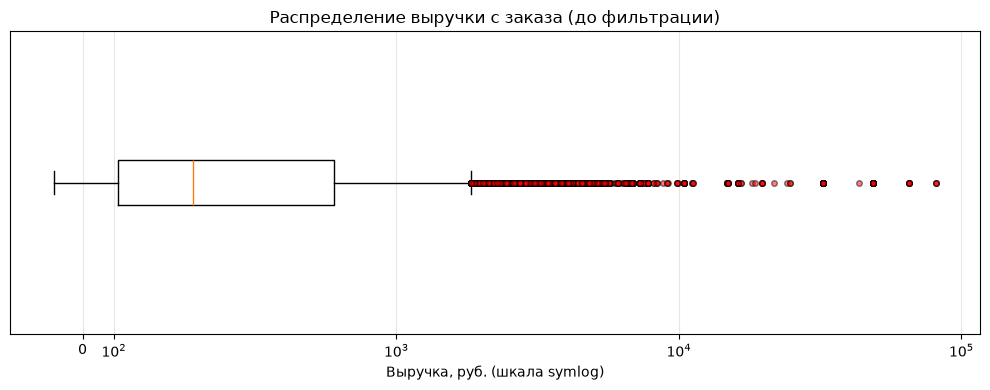

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.boxplot(
    df['revenue_rub'].dropna(),
    orientation='horizontal',
    showfliers=True,
    flierprops=dict(
        marker='o',
        markerfacecolor='red',
        markersize=4,
        alpha=0.5,
    ),
)

# symlog scale: около нуля шкала линейная, а дальше — логарифмическая.
ax.set_xscale('symlog', linthresh=1000)

ax.set_title('Распределение выручки с заказа (до фильтрации)')
ax.set_xlabel('Выручка, руб. (шкала symlog)')
ax.set_yticks([])
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

Среднее примерно в 1.6 раза выше медианы. В сочетании с длинным правым хвостом на графике это указывает на правостороннюю асимметрию: крупные значения выручки повышают среднее.

Наблюдается значительный разброс выручки (`std ≈ 875.5`) и присутствуют крупные значения, требующие дополнительной проверки. Также необходимо уточнить причину отрицательной выручки.


Удалим строки, в которых `revenue_rub` выше 99-го перцентиля:

In [29]:
rows_before = len(df)
threshold = df['revenue_rub'].quantile(0.99)

df = df.loc[df['revenue_rub'] <= threshold].copy()

rows_removed = rows_before - len(df)
removed_percent = rows_removed / rows_before * 100

print(f'99-й перцентиль: {threshold:.2f} руб.')
print(f'Строк до фильтрации: {rows_before}')
print(f'Строк после фильтрации: {len(df)}')
print(f'Удалено: {rows_removed} строк ({removed_percent:.2f}%)')

99-й перцентиль: 2628.42 руб.
Строк до фильтрации: 290611
Строк после фильтрации: 287786
Удалено: 2825 строк (0.97%)


In [30]:
df.info()

<class 'pandas.DataFrame'>
Index: 287786 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                287786 non-null  str           
 1   device_type_canonical  287786 non-null  str           
 2   order_id               287786 non-null  int32         
 3   order_dt               287786 non-null  datetime64[us]
 4   order_ts               287786 non-null  datetime64[us]
 5   currency_code          287786 non-null  str           
 6   revenue                287786 non-null  float64       
 7   tickets_count          287786 non-null  int32         
 8   days_since_prev        266060 non-null  float32       
 9   event_id               287786 non-null  int32         
 10  event_name             287786 non-null  str           
 11  event_type_main        287786 non-null  str           
 12  service_name           287786 non-null  str           
 13  

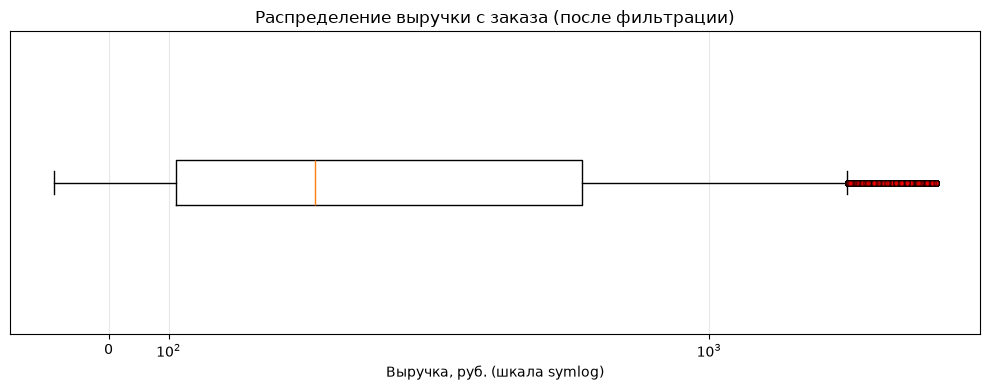

In [31]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.boxplot(
    df['revenue_rub'].dropna(),
    orientation='horizontal',
    showfliers=True,
    flierprops=dict(
        marker='o',
        markerfacecolor='red',
        markersize=4,
        alpha=0.5,
    ),
)

ax.set_xscale('symlog', linthresh=1000)

ax.set_title('Распределение выручки с заказа (после фильтрации)')
ax.set_xlabel('Выручка, руб. (шкала symlog)')
ax.set_yticks([])
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Проверим данные в столбце `tickets_count`.

In [32]:
df['tickets_count'].describe()

count    287786.000000
mean          2.740495
std           1.163073
min           1.000000
25%           2.000000
50%           3.000000
75%           3.000000
max          57.000000
Name: tickets_count, dtype: float64

Построим гистограмму и диаграмму размаха для столбца `tickets_count`:

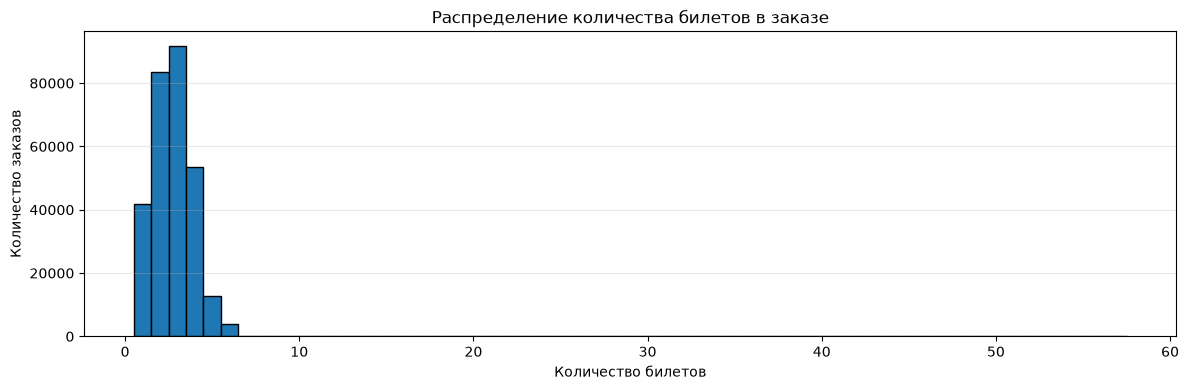

In [33]:
tickets = df['tickets_count']
bins = [x - 0.5 for x in range(int(tickets.min()), int(tickets.max()) + 2)]

plt.figure(figsize=(12, 4))
plt.hist(tickets, bins=bins, edgecolor='black')

plt.title('Распределение количества билетов в заказе')
plt.xlabel('Количество билетов')
plt.ylabel('Количество заказов')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

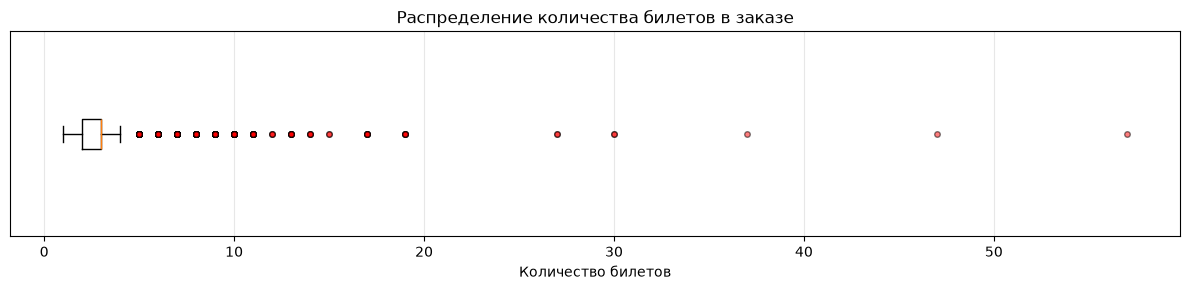

In [34]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 3))

ax.boxplot(
    df['tickets_count'],
    orientation='horizontal',
    showfliers=True,
    flierprops=dict(
        marker='o',
        markerfacecolor='red',
        markersize=4,
        alpha=0.5,
    ),
)

ax.set_title('Распределение количества билетов в заказе')
ax.set_xlabel('Количество билетов')
ax.set_yticks([])
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

Количество билетов в заказе преимущественно составляет от 1 до 4. Наиболее распространены заказы на 3 билета.

Справа видны значения около 27, 30, 37, 47 и 57 билетов. Они заметно отличаются от типичных и могут соответствовать групповым покупкам.

Промежуточные **выводы после предобработки**:
- Оптимизированы типы данных для столбцов: `order_id`, `tickets_count`, `event_id`, `days_since_prev`.
- Изучены пропуски в данных. Пропуски обнаружились только в столбце `days_since_prev`.
- После фильтрации в столбце `revenue_rub` **удалено 2825 строк (0.97% данных)**.


## 3. Создание профиля пользователя

### 3.1. Строим профиль пользователя

In [35]:
df.info()

<class 'pandas.DataFrame'>
Index: 287786 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                287786 non-null  str           
 1   device_type_canonical  287786 non-null  str           
 2   order_id               287786 non-null  int32         
 3   order_dt               287786 non-null  datetime64[us]
 4   order_ts               287786 non-null  datetime64[us]
 5   currency_code          287786 non-null  str           
 6   revenue                287786 non-null  float64       
 7   tickets_count          287786 non-null  int32         
 8   days_since_prev        266060 non-null  float32       
 9   event_id               287786 non-null  int32         
 10  event_name             287786 non-null  str           
 11  event_type_main        287786 non-null  str           
 12  service_name           287786 non-null  str           
 13  

Отсортируем данные по времени совершения заказа:

In [36]:
df = df.sort_values(by='order_ts')

Для каждого пользователя найдем агрегированные признаки:

In [37]:
user_profile = df.groupby('user_id', as_index=False).agg(
    first_order_dt=('order_dt', 'min'),
    last_order_dt=('order_dt', 'max'),
    first_device=('device_type_canonical', 'first'),
    first_region=('region_name', 'first'),
    first_partner=('service_name', 'first'),
    first_event_type=('event_type_main', 'first'),
    total_orders=('order_id', 'count'),
    avg_revenue_rub=('revenue_rub', 'mean'),
    avg_tickets_count=('tickets_count', 'mean'),
    avg_days_between=('days_since_prev', 'mean')
)

Добавим бинарные признаки:

In [38]:
user_profile['is_two'] = user_profile['total_orders'] >= 2
user_profile['is_five'] = user_profile['total_orders'] >= 5

user_profile.head()

,user_id,first_order_dt,last_order_dt,first_device,first_region,first_partner,first_event_type,total_orders,avg_revenue_rub,avg_tickets_count,avg_days_between,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,Край билетов,театр,1,1521.940000,4.000000,NaN,False,False
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,Мой билет,выставки,2,774.010000,3.000000,75.0,True,False
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,Лови билет!,другое,3,767.213333,2.666667,51.0,True,False
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,Край билетов,театр,1,917.830000,4.000000,NaN,False,False
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,Лучшие билеты,театр,2,61.310000,1.500000,16.0,True,False


In [39]:
user_profile.info()

<class 'pandas.DataFrame'>
RangeIndex: 21854 entries, 0 to 21853
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            21854 non-null  str           
 1   first_order_dt     21854 non-null  datetime64[us]
 2   last_order_dt      21854 non-null  datetime64[us]
 3   first_device       21854 non-null  str           
 4   first_region       21854 non-null  str           
 5   first_partner      21854 non-null  str           
 6   first_event_type   21854 non-null  str           
 7   total_orders       21854 non-null  int64         
 8   avg_revenue_rub    21854 non-null  float64       
 9   avg_tickets_count  21854 non-null  float64       
 10  avg_days_between   13521 non-null  float32       
 11  is_two             21854 non-null  bool          
 12  is_five            21854 non-null  bool          
dtypes: bool(2), datetime64[us](2), float32(1), float64(2), int64(1), str(5)


### 3.2. Изучаем данные: насколько они репрезентативны и нет ли в них аномалий

In [40]:
print(f'Общее число пользователей: {user_profile.shape[0]}')

avg_revenue_per_order = (
    (user_profile['avg_revenue_rub'] * user_profile['total_orders']).sum()
    / user_profile['total_orders'].sum()
)
print(f'Средняя выручка с одного заказа: {avg_revenue_per_order:.2f} руб.')

share_two = round(user_profile['is_two'].mean() * 100, 2)
print(f'Доля пользователей, совершивших 2 и более заказа: {share_two:.2f}%')

share_five = round(user_profile['is_five'].mean() * 100, 2)
print(f'Доля пользователей, совершивших 5 и более заказов: {share_five:.2f}%')

Общее число пользователей: 21854
Средняя выручка с одного заказа: 518.03 руб.
Доля пользователей, совершивших 2 и более заказа: 61.71%
Доля пользователей, совершивших 5 и более заказов: 29.01%


Статистические показатели по общему числу заказов:

In [41]:
user_profile['total_orders'].describe()

count    21854.000000
mean        13.168573
std        121.674800
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max      10181.000000
Name: total_orders, dtype: float64

по среднему числу билетов в заказе:

In [42]:
user_profile['avg_tickets_count'].describe()

count    21854.000000
mean         2.743129
std          0.913080
min          1.000000
25%          2.000000
50%          2.750000
75%          3.076923
max         11.000000
Name: avg_tickets_count, dtype: float64

по среднему количеству дней между покупками:

In [43]:
user_profile['avg_days_between'].describe()

count    13521.000000
mean        15.836109
std         22.297926
min          0.000000
25%          1.000000
50%          8.000000
75%         20.400000
max        148.000000
Name: avg_days_between, dtype: float64

Общее число пользователей в выборке равно 21854. Этого объема достаточно для анализа.

В столбце `total_orders` есть аномальные значения: максимальное число заказов у одного пользователя достигает 10181. Попробуем понять, что с этим делать.

In [44]:
user_profile['total_orders'].quantile([0.9, 0.95, 0.99, 0.999])

0.900      15.000
0.950      31.350
0.990     152.000
0.999    1461.969
Name: total_orders, dtype: float64

Порог по 99.9% убирает только самые экстремальные случаи. При этом остается группа пользователей со 152 - 1461 заказами. Это уже очень много для одного человека, а на среднее значение такие пользователи влияют заметно.

Порог по 99% убирает весь "тяжелый хвост", однако вместе с аномалиями могут уйти и реальные очень активные пользователи. С другой стороны, при таком разрыве между 95-м (31) и 99-м (152) перцентилями потеря около 1% данных допустима.

Поэтому отфильтруем данные по 99-му перцентилю.

In [45]:
rows_before = len(user_profile)
threshold = user_profile['total_orders'].quantile(0.99)

user_profile = user_profile.loc[user_profile['total_orders'] <= threshold].copy()

rows_removed = rows_before - len(user_profile)
removed_percent = rows_removed / rows_before * 100

print(f'99-й перцентиль: {threshold:.2f} заказов')
print(f'Строк до фильтрации: {rows_before}')
print(f'Строк после фильтрации: {len(user_profile)}')
print(f'Удалено: {rows_removed} строк ({removed_percent:.2f}%)')

99-й перцентиль: 152.00 заказов
Строк до фильтрации: 21854
Строк после фильтрации: 21638
Удалено: 216 строк (0.99%)


Выведем статистические показатели по обновлённому датасету:

In [46]:
user_profile.describe()

,first_order_dt,last_order_dt,total_orders,avg_revenue_rub,avg_tickets_count,avg_days_between
count,21638,21638,21638.000000,21638.000000,21638.000000,13305.000000
mean,2024-08-10 15:16:15.284222,2024-09-17 21:56:17.058878,6.501294,544.707837,2.743319,16.085749
min,2024-06-01 00:00:00,2024-06-01 00:00:00,1.000000,-10.770000,1.000000,0.000000
25%,2024-06-26 00:00:00,2024-08-24 00:00:00,1.000000,209.772500,2.000000,1.333333
50%,2024-08-09 00:00:00,2024-10-02 00:00:00,2.000000,463.498333,2.750000,8.333333
75%,2024-09-23 00:00:00,2024-10-22 00:00:00,5.000000,768.156375,3.095238,20.750000
max,2024-10-31 00:00:00,2024-10-31 00:00:00,152.000000,2628.421739,11.000000,148.000000
std,NaN,NaN,14.324031,433.624438,0.917486,22.391232


## 4. Исследовательский анализ данных

### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Изучим распределение пользователей по признакам.

In [47]:
user_profile.info()

<class 'pandas.DataFrame'>
Index: 21638 entries, 0 to 21853
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            21638 non-null  str           
 1   first_order_dt     21638 non-null  datetime64[us]
 2   last_order_dt      21638 non-null  datetime64[us]
 3   first_device       21638 non-null  str           
 4   first_region       21638 non-null  str           
 5   first_partner      21638 non-null  str           
 6   first_event_type   21638 non-null  str           
 7   total_orders       21638 non-null  int64         
 8   avg_revenue_rub    21638 non-null  float64       
 9   avg_tickets_count  21638 non-null  float64       
 10  avg_days_between   13305 non-null  float32       
 11  is_two             21638 non-null  bool          
 12  is_five            21638 non-null  bool          
dtypes: bool(2), datetime64[us](2), float32(1), float64(2), int64(1), str(5)
memor

In [48]:
features = {
    'first_event_type': 'тип первого мероприятия',
    'first_device': 'устройство первой покупки',
    'first_region': 'регион первого заказа',
    'first_partner': 'билетный оператор первого заказа',
}

def segment_table(col):
    res = (
        user_profile.groupby(col)
          .agg(users=('user_id', 'count'))
          .sort_values('users', ascending=False)
    )
    res['share'] = (res['users'] / res['users'].sum() * 100).round(2)
    return res

for col, title in features.items():
    print(f'Распределение по признаку: {title}')
    display(segment_table(col))

Распределение по признаку: тип первого мероприятия


,users,share
first_event_type,,
концерты,9560,44.18
другое,5426,25.08
театр,4239,19.59
стендап,1110,5.13
спорт,794,3.67
выставки,414,1.91
ёлки,95,0.44


Распределение по признаку: устройство первой покупки


,users,share
first_device,,
mobile,17924,82.84
desktop,3714,17.16


Распределение по признаку: регион первого заказа


,users,share
first_region,,
Каменевский регион,7085,32.74
Североярская область,3767,17.41
Широковская область,1224,5.66
Озернинский край,675,3.12
Малиновоярский округ,525,2.43
...,...,...
Залесский край,2,0.01
Тихогорская область,2,0.01
Верхозёрский край,1,0.00


Распределение по признаку: билетный оператор первого заказа


,users,share
first_partner,,
Билеты без проблем,5186,23.97
Мой билет,2969,13.72
Лови билет!,2809,12.98
Билеты в руки,2559,11.83
Облачко,2177,10.06
Весь в билетах,1285,5.94
Лучшие билеты,1184,5.47
Прачечная,583,2.69
Край билетов,454,2.10


Ни в одном из сегментов пользователи не распределены равномерно.

По *типу первого мероприятия* есть выраженная "точка входа": концерты (44%). Значимые вторичные сегменты: "другое" (25%) и театр (20%). Стендап, спорт, выставки и елки образуют нишевые сегменты, у каждого доля 0.4-5%.

По *устройству первой покупки* распределение сильно смещено в сторону мобильных (82.8% пользователей).

По *региону первого заказа* есть две выраженные точки входа (Каменевский регион - 33%, Североярская область - 17%), а остальные регионы образуют длинный хвост, в котором у многих регионов лишь единицы пользователей.

По *билетному оператору* выраженные точки входа такие: "Билеты без проблем" (24%), "Мой билет" (14%), "Лови билет!" (13%), "Билеты в руки" (12%) и "Облачко" (10%). Вместе они дают около 73% пользователей. Остальные операторы образуют длинный хвост, в котором у многих меньше 100 пользователей.

Проанализируем возвраты пользователей.

,users,repeat_users,repeat_share
first_event_type,,,
выставки,414,265,64.01
театр,4239,2687,63.39
концерты,9560,5911,61.83
стендап,1110,676,60.90
другое,5426,3235,59.62
спорт,794,443,55.79
ёлки,95,53,55.79


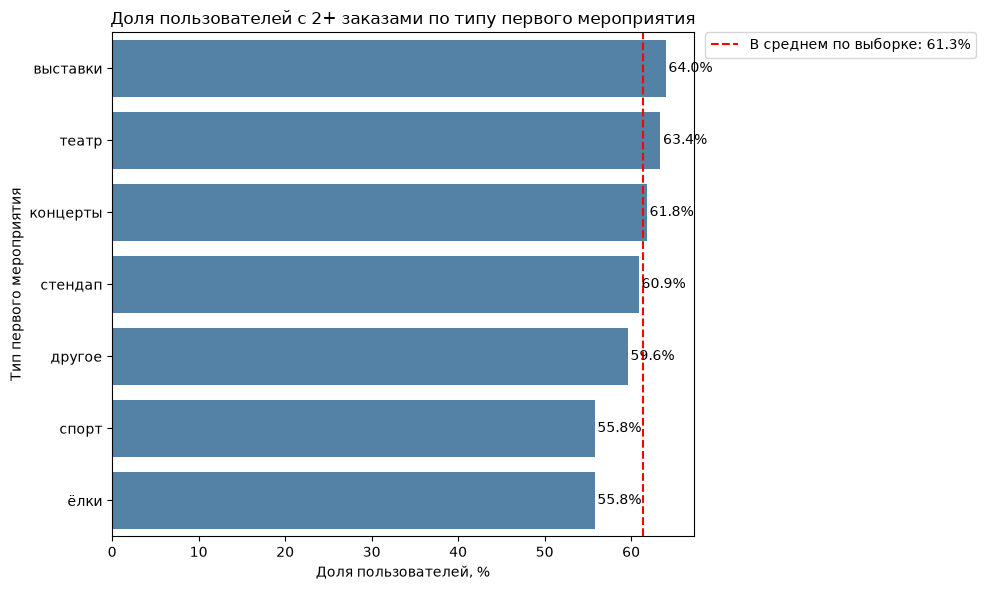

In [49]:
repeat_by_type = (
    user_profile.groupby('first_event_type')
        .agg(users=('user_id', 'count'),
             repeat_users=('is_two', 'sum'),
             repeat_share=('is_two', 'mean'))
        .sort_values('repeat_share', ascending=False)
)
repeat_by_type['repeat_share'] = (repeat_by_type['repeat_share'] * 100).round(2)
display(repeat_by_type)

overall = user_profile['is_two'].mean() * 100

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=repeat_by_type.reset_index(),
    x='repeat_share', y='first_event_type',
    color='steelblue'
)
ax.axvline(overall, color='red', linestyle='--', label=f'В среднем по выборке: {overall:.1f}%')
for p in ax.patches:
    ax.text(p.get_width() + 0.3, p.get_y() + p.get_height() / 2,
            f'{p.get_width():.1f}%', va='center')
ax.set_title('Доля пользователей с 2+ заказами по типу первого мероприятия')
ax.set_xlabel('Доля пользователей, %')
ax.set_ylabel('Тип первого мероприятия')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

- Разброс между сегментами небольшой: от 55.8% до 64%.
- *Какие сегменты возвращаются чаще.*
  
  ВЫШЕ СРЕДНЕГО по выборке — выставки (64%) и театр (63.4%) ; НА УРОВНЕ СРЕДНЕГО — концерты (61.8%) и стендап (60.9%) ; НИЖЕ СРЕДНЕГО — "другое" (59.6%), спорт и елки (по 55.8%).
- В сегменте "елки" всего 95 пользователей, и 53 из них (56%) совершили 2 и более заказа. Выборка слишком мала, а сегмент, скорее всего, сезонный и нишевый, поэтому надёжных выводов по нему сделать нельзя.
- Театр можно назвать успешной точкой входа: сегмент крупный (около 20% пользователей), а повторные заказы встречаются чаще среднего.
- Концерты дают основной поток пользователей (44%), но возвращаются они на уровне среднего.
- Выставки выглядят перспективно, но данных мало.
- Пользователи, начавшие с театра, возвращаются чуть чаще, а начавшие со спорта чуть реже.

,users,repeat_users,repeat_share
first_device,,,
desktop,3714,2370,63.81
mobile,17924,10900,60.81


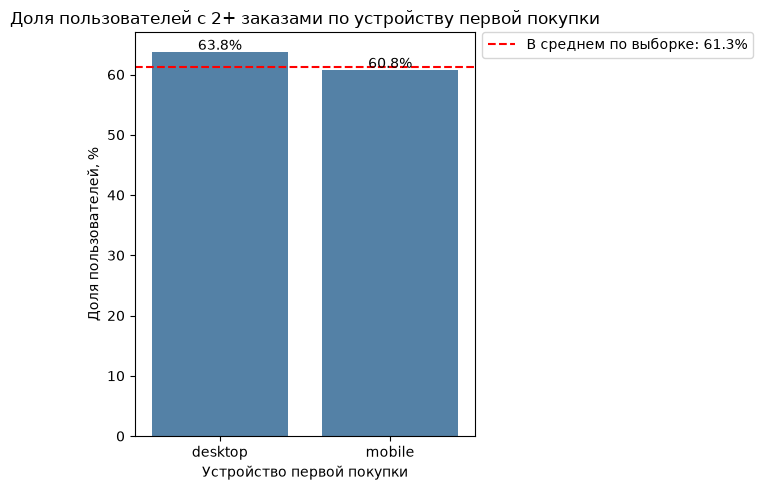

In [50]:
repeat_by_device = (
    user_profile.groupby('first_device')
        .agg(users=('user_id', 'count'),
             repeat_users=('is_two', 'sum'),
             repeat_share=('is_two', 'mean'))
        .sort_values('repeat_share', ascending=False)
)
repeat_by_device['repeat_share'] = (repeat_by_device['repeat_share'] * 100).round(2)
display(repeat_by_device)

overall = user_profile['is_two'].mean() * 100

plt.figure(figsize=(7, 5))
ax = sns.barplot(
    data=repeat_by_device.reset_index(),
    x='first_device', y='repeat_share',
    color='steelblue'
)
ax.axhline(overall, color='red', linestyle='--', label=f'В среднем по выборке: {overall:.1f}%')
for p in ax.patches:
    ax.text(p.get_x() + p.get_width() / 2, p.get_height() + 0.3,
            f'{p.get_height():.1f}%', ha='center')
ax.set_title('Доля пользователей с 2+ заказами по устройству первой покупки')
ax.set_xlabel('Устройство первой покупки')
ax.set_ylabel('Доля пользователей, %')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

- Сегментов два, и разница между ними небольшая.
- *Какие сегменты возвращаются чаще.*
  
  desktop: 63.8%, это ВЫШЕ СРЕДНЕГО ; mobile: 60.8%, это НА УРОВНЕ СРЕДНЕГО или чуть НИЖЕ.
- Оба сегмента крупные, поэтому доли стабильны.
- Пользователи, впервые купившие с компьютера, чуть чаще делают повторный заказ. Причину по этим данным назвать нельзя.



,users,repeat_users,repeat_share
first_region,,,
Каменевский регион,7085,4421,62.40
Североярская область,3767,2404,63.82
Широковская область,1224,790,64.54
Озернинский край,675,373,55.26
Малиновоярский округ,525,294,56.00
Шанырский регион,500,336,67.20
Травяная область,488,300,61.48
Светополянский округ,457,300,65.65
Речиновская область,440,279,63.41


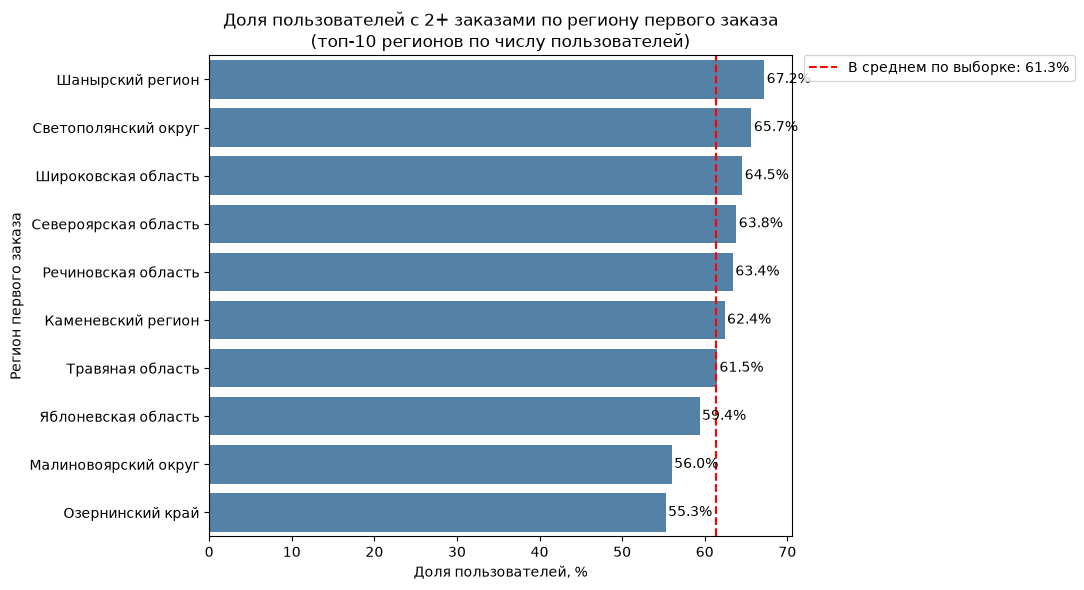

In [51]:
repeat_by_region = (
    user_profile.groupby('first_region')
        .agg(users=('user_id', 'count'),
             repeat_users=('is_two', 'sum'),
             repeat_share=('is_two', 'mean'))
        .sort_values('users', ascending=False)
)
repeat_by_region['repeat_share'] = (repeat_by_region['repeat_share'] * 100).round(2)

# 10 регионов с наибольшим числом пользователей
top_regions = repeat_by_region.head(10)
display(top_regions)

overall = user_profile['is_two'].mean() * 100

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=top_regions.reset_index().sort_values('repeat_share', ascending=False),
    x='repeat_share', y='first_region',
    color='steelblue'
)
ax.axvline(overall, color='red', linestyle='--', label=f'В среднем по выборке: {overall:.1f}%')
for p in ax.patches:
    ax.text(p.get_width() + 0.3, p.get_y() + p.get_height() / 2,
            f'{p.get_width():.1f}%', va='center')
ax.set_title('Доля пользователей с 2+ заказами по региону первого заказа\n(топ-10 регионов по числу пользователей)')
ax.set_xlabel('Доля пользователей, %')
ax.set_ylabel('Регион первого заказа')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

- На графике показаны 10 регионов с наибольшим числом пользователей, всего их 81. В топ‑10 входит около 72% пользователей. Доли в топ‑10 лежат в диапазоне от 55.3% до 67.2%.
- *Какие сегменты возвращаются чаще.*
  
  ВЫШЕ СРЕДНЕГО по выборке — Шанырский регион (67.2%), Светополянский округ (65.7%), Широковская область (64.5%), Североярская область (63.8%) и Речиновская область (63.4%) ; НА УРОВНЕ СРЕДНЕГО — Каменевский регион (62.4%) и Травяная область (61.5%) ; НИЖЕ СРЕДНЕГО — Яблоневская область (59.4%), Малиновоярский округ (56.0%) и Озернинский край (55.3%).


,users,repeat_users,repeat_share
first_partner,,,
Билеты без проблем,5186,3133,60.41
Мой билет,2969,1807,60.86
Лови билет!,2809,1711,60.91
Билеты в руки,2559,1605,62.72
Облачко,2177,1334,61.28
Весь в билетах,1285,808,62.88
Лучшие билеты,1184,725,61.23
Прачечная,583,365,62.61
Край билетов,454,296,65.20


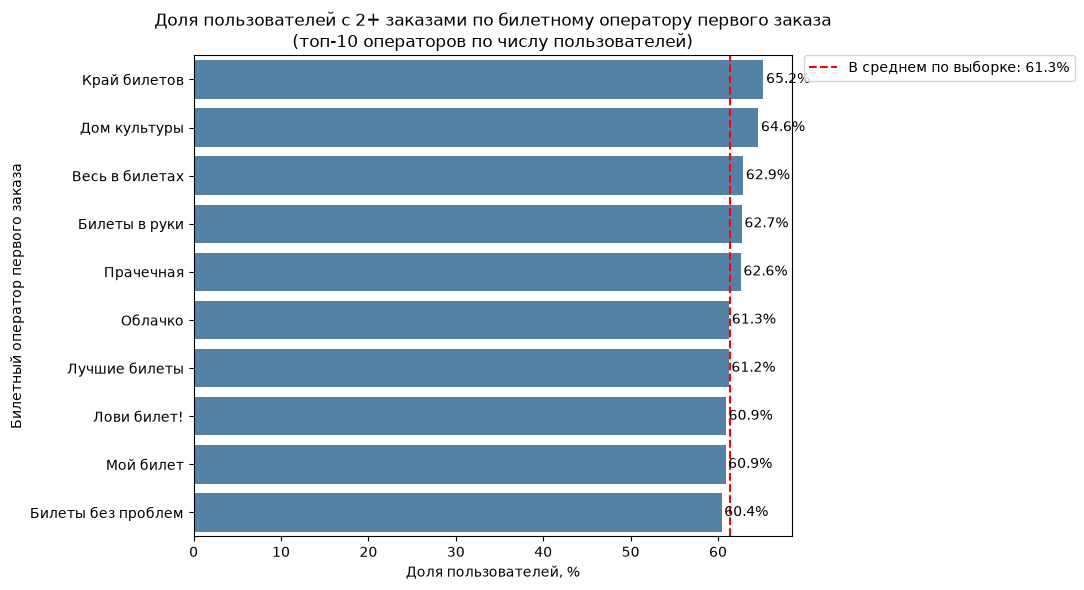

In [52]:
repeat_by_partner = (
    user_profile.groupby('first_partner')
        .agg(users=('user_id', 'count'),
             repeat_users=('is_two', 'sum'),
             repeat_share=('is_two', 'mean'))
        .sort_values('users', ascending=False)
)
repeat_by_partner['repeat_share'] = (repeat_by_partner['repeat_share'] * 100).round(2)

top_partners = repeat_by_partner.head(10)
display(top_partners)

overall = user_profile['is_two'].mean() * 100

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=top_partners.reset_index().sort_values('repeat_share', ascending=False),
    x='repeat_share', y='first_partner',
    color='steelblue'
)
ax.axvline(overall, color='red', linestyle='--', label=f'В среднем по выборке: {overall:.1f}%')
for p in ax.patches:
    ax.text(p.get_width() + 0.3, p.get_y() + p.get_height() / 2,
            f'{p.get_width():.1f}%', va='center')
ax.set_title('Доля пользователей с 2+ заказами по билетному оператору первого заказа\n(топ-10 операторов по числу пользователей)')
ax.set_xlabel('Доля пользователей, %')
ax.set_ylabel('Билетный оператор первого заказа')
ax.legend(loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

- На графике показан топ-10 билетных операторов и их доли лежат в узком диапазоне 60.4-65.2%.
- Оператор первого заказа практически не влияет на вероятность вернуться.
- "Края билетов" (65.2%) и "Дом культуры" (64.6%) показывают лучшие результаты, но из-за небольшого размера сегментов (350–450 пользователей) эти значения недостаточно надежны.

Проверим продуктовые гипотезы.

**Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.

**Решение: гипотеза не подтверждается.** Спортивные мероприятия дают не большую, а меньшую долю повторных заказов (55.79% vs 61.83%).

**Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

**Решение: гипотеза не подтверждается.** Гипотеза предполагает, что чем больше пользователей в регионе, тем выше доля повторных заказов. По данным этого не видно. Среди топ-10 регионов доля повторных заказов не растет вместе с числом пользователей, например, лидеры по доле (Шанырский регион, Светополянский округ) входят в число менее крупных.

### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

In [53]:
user_profile.info()

<class 'pandas.DataFrame'>
Index: 21638 entries, 0 to 21853
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            21638 non-null  str           
 1   first_order_dt     21638 non-null  datetime64[us]
 2   last_order_dt      21638 non-null  datetime64[us]
 3   first_device       21638 non-null  str           
 4   first_region       21638 non-null  str           
 5   first_partner      21638 non-null  str           
 6   first_event_type   21638 non-null  str           
 7   total_orders       21638 non-null  int64         
 8   avg_revenue_rub    21638 non-null  float64       
 9   avg_tickets_count  21638 non-null  float64       
 10  avg_days_between   13305 non-null  float32       
 11  is_two             21638 non-null  bool          
 12  is_five            21638 non-null  bool          
dtypes: bool(2), datetime64[us](2), float32(1), float64(2), int64(1), str(5)
memor

Проследим связь между средней выручкой сервиса с заказа и повторными заказами.

In [54]:
def plot_hist(df, column, groupby, title, xlabel, ylabel, binwidth, kde=False, labels=None):
    '''
    Функция для визуализации распределения значений с учётом категорий и линией KDE.
    Параметры:
    df - датафрейм с данными для анализа.
    column - str, название столбца, значения которого будут отображаться на графике.
    groupby - str, название столбца, по которому будет производиться группировка данных.
    binwidth - int, ширина корзины для гистограммы.
    title - str, заголовок графика.
    xlabel - str, подпись по оси X.
    ylabel - str, подпись по оси Y.
    kde - наложение графика KDE на гистограмму
    labels - dict, подписи для значений groupby в легенде, например {False: 'Один заказ'}
    '''

    plt.figure(figsize=(9, 4))

    min_value = int(np.floor(df[column].min()))
    max_value = int(np.ceil(df[column].max()))
    bins = np.arange(min_value, max_value + binwidth, binwidth)

    groups = sorted(df[groupby].unique())
    labels = labels or {}

    for value in groups:
        name = labels.get(value, f'{groupby}: {value}')
        df.loc[df[groupby] == value, column].plot(
            kind='hist',
            density=True,
            bins=bins,
            alpha=0.5,
            label=f'{name} (n={(df[groupby] == value).sum():,})'.replace(',', ' '),
            legend=True
        )

    if kde:
        for value in groups:
            name = labels.get(value, f'{groupby}: {value}')
            df.loc[df[groupby] == value, column].plot(
                kind='kde',
                label=f'Кривая плотности: {name}',
            )

    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend()
    plt.xlim(min_value, max_value)

    plt.grid()
    plt.show()

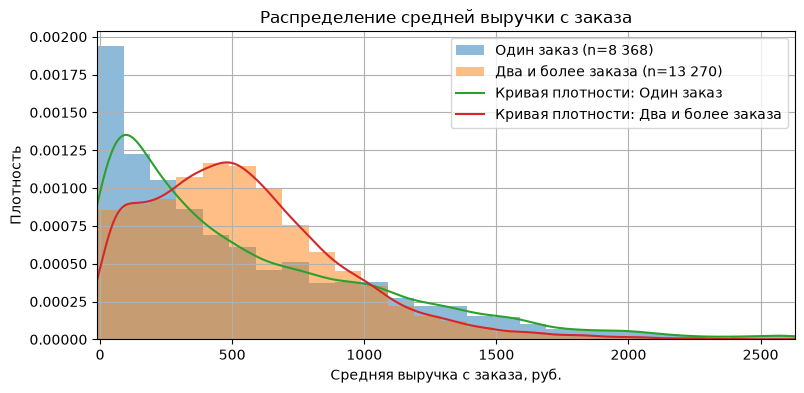

In [55]:
plot_hist(
    df=user_profile,
    column='avg_revenue_rub',
    groupby='is_two',
    binwidth=100,
    title='Распределение средней выручки с заказа',
    xlabel='Средняя выручка с заказа, руб.',
    ylabel='Плотность',
    kde=True,
    labels={False: 'Один заказ', True: 'Два и более заказа'},
)

- **Один заказ:** основная масса сосредоточена в диапазоне примерно до 500 руб. с резким пиком в 0–100 руб. (плотность около 0.0019, то есть порядка 19% группы в одной корзине). Дальше плотность быстро падает, есть длинный правый хвост до 2500+ руб.
- **Два и более заказа:** распределение смещено вправо относительно группы с одним заказом. Основная масса приходится на 200–900 руб., мода около 400–600 руб.
- Пользователи с одним заказом заметно чаще имеют очень низкую среднюю выручку (до 100–200 руб.). Вернувшиеся пользователи в этой зоне встречаются реже.
- В диапазоне 300–900 руб. картина обратная: вернувшихся пользователей там больше.
- Выше примерно 1100 руб. распределения почти совпадают. Хвост у группы "один заказ" чуть тяжелее.

Сравним распределение по средней выручке с заказа в двух группах пользователей (совершивших 2–4 заказа и совершивших 5 и более заказов).

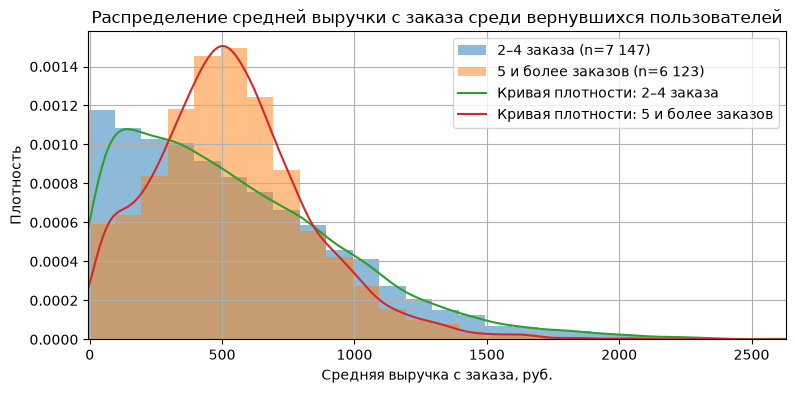

In [56]:
plot_hist(
    df=user_profile[user_profile['is_two']],
    column='avg_revenue_rub',
    groupby='is_five',
    binwidth=100,
    title='Распределение средней выручки с заказа среди вернувшихся пользователей',
    xlabel='Средняя выручка с заказа, руб.',
    ylabel='Плотность',
    kde=True,
    labels={False: '2–4 заказа', True: '5 и более заказов'},
)

Пользователи с 2-4 заказами чаще имеют низкую среднюю выручку (до 200-300 руб.). Пользователи с 5+ заказами чаще сосредоточены вокруг "типичного" значения 400-700 руб. При выручке выше 800-1000 руб. группы различаются слабо.

Проанализируем влияние среднего количества билетов в заказе на вероятность повторной покупки.

count    21638.000000
mean         2.743319
std          0.917486
min          1.000000
25%          2.000000
50%          2.750000
75%          3.095238
max         11.000000
Name: avg_tickets_count, dtype: float64
0.50    2.75
0.90    4.00
0.95    4.00
0.99    5.00
Name: avg_tickets_count, dtype: float64


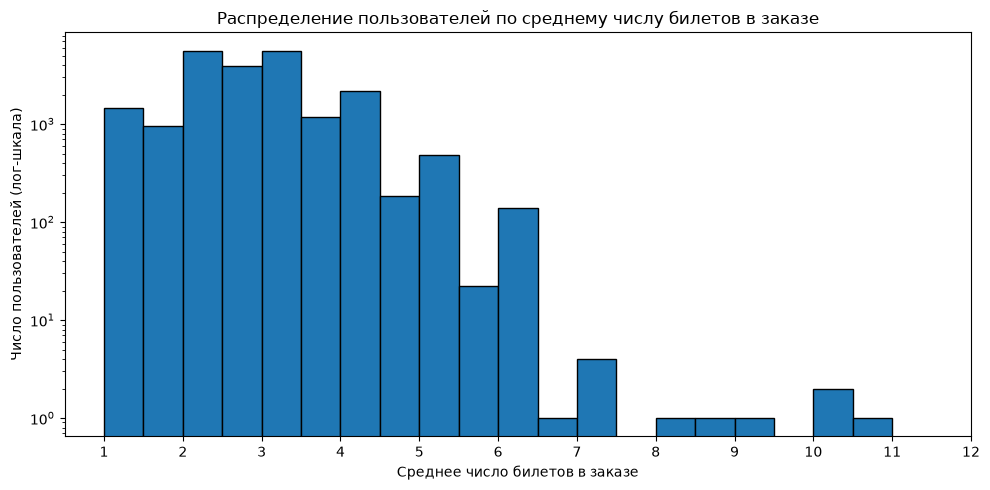

In [57]:
col = user_profile['avg_tickets_count']
print(col.describe())
print(col.quantile([.5, .9, .95, .99]))

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(col, bins=np.arange(1, col.max() + 0.5, 0.5), edgecolor='black')
ax.set_yscale('log')

ax.set_title('Распределение пользователей по среднему числу билетов в заказе')
ax.set_xlabel('Среднее число билетов в заказе')
ax.set_ylabel('Число пользователей (лог-шкала)')
ax.set_xticks(range(1, int(col.max()) + 2))

plt.tight_layout()
plt.show()

- Большинство пользователей берут от 2 до 4 билетов за заказ. Среднее (2.74) почти совпадает с медианой (2.75), поэтому типичный заказ рассчитан на двух / трех человек.
- Распределение слегка скошено вправо: значения выше 5 встречаются редко (около 1% пользователей), а максимум достигает 11.
- Больше всего пользователей со средним числом билетов от 2 до 3 и от 3 до 5, а сегмент "5 и более" совсем немногочисленный.

Разделим пользователей на несколько сегментов по среднему количеству билетов в заказе и для каждого сегмента подсчитаем общее число пользователей и долю пользователей, совершивших повторные заказы:

In [58]:
def get_segment(x):
    if x < 2:
        return 'от 1 до 2'
    elif x < 3:
        return 'от 2 до 3'
    elif x < 5:
        return 'от 3 до 5'
    else:
        return '5 и более'

user_profile['tickets_segment'] = user_profile['avg_tickets_count'].apply(get_segment)

segments = ['от 1 до 2', 'от 2 до 3', 'от 3 до 5', '5 и более']
rows = []

for segment in segments:
    group = user_profile[user_profile['tickets_segment'] == segment]
    users = len(group)
    repeat_users = group['is_two'].sum()
    repeat_share = round(repeat_users / users * 100, 2)
    rows.append([segment, users, repeat_users, repeat_share])

segment_stats = pd.DataFrame(
    rows,
    columns=['tickets_segment', 'users', 'repeat_users', 'repeat_share']
)
segment_stats

,tickets_segment,users,repeat_users,repeat_share
0,от 1 до 2,2419,1241,51.30
1,от 2 до 3,9498,6989,73.58
2,от 3 до 5,9060,4916,54.26
3,5 и более,661,124,18.76


Распределение по сегментам сконцентрировано: около 86% пользователей приходится на два сегмента ("от 2 до 3" и "от 3 до 5"). Сегмент "от 1 до 2" небольшой, а "5 и более" совсем маленький.

Аномально низкая доля у "5 и более": возвращается меньше каждого пятого пользователя, в разы меньше, чем в остальных сегментах. Возможно, что такие большие заказы чаще разовые (мероприятия для компании или семьи), а не регулярные покупки.

Аномально высокая доля у "от 2 до 3": почти три из четырёх пользователей делают повторный заказ. Этот сегмент еще и самый большой.

### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

In [59]:
user_profile.info()

<class 'pandas.DataFrame'>
Index: 21638 entries, 0 to 21853
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            21638 non-null  str           
 1   first_order_dt     21638 non-null  datetime64[us]
 2   last_order_dt      21638 non-null  datetime64[us]
 3   first_device       21638 non-null  str           
 4   first_region       21638 non-null  str           
 5   first_partner      21638 non-null  str           
 6   first_event_type   21638 non-null  str           
 7   total_orders       21638 non-null  int64         
 8   avg_revenue_rub    21638 non-null  float64       
 9   avg_tickets_count  21638 non-null  float64       
 10  avg_days_between   13305 non-null  float32       
 11  is_two             21638 non-null  bool          
 12  is_five            21638 non-null  bool          
 13  tickets_segment    21638 non-null  str           
dtypes: bool(2), datetime64

Проанализируем, как день недели, в который была совершена первая покупка, влияет на поведение пользователей.

In [60]:
weekday_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']

def share_in_percent(s):
    return round(s.mean() * 100, 2)

weekday_stats = (
    user_profile
    .groupby(user_profile['first_order_dt'].dt.day_of_week)
    .agg(
        users=('user_id', 'nunique'),
        repeat_users=('is_two', 'sum'),
        repeat_share_pct=('is_two', share_in_percent)
    )
)
weekday_stats.index = weekday_names
display(weekday_stats)

,users,repeat_users,repeat_share_pct
Пн,2930,1847,63.04
Вт,3176,1966,61.90
Ср,3057,1901,62.19
Чт,3113,1850,59.43
Пт,3259,1950,59.83
Сб,3326,2089,62.81
Вс,2777,1667,60.03


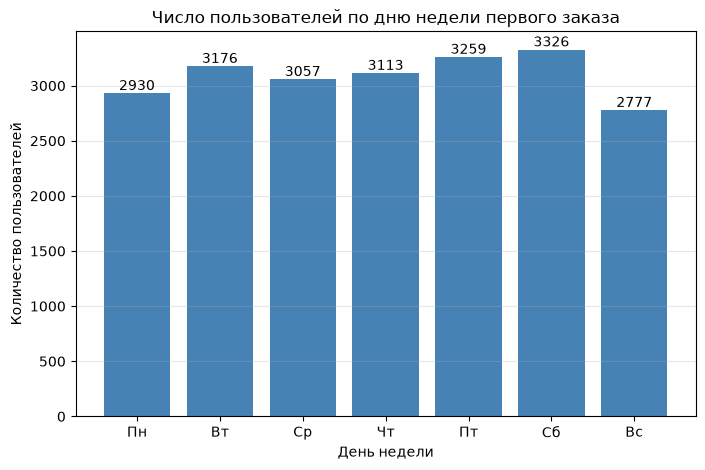

In [61]:
plt.figure(figsize=(8, 5))
plt.bar(weekday_stats.index, weekday_stats['users'], color='steelblue')

plt.title('Число пользователей по дню недели первого заказа')
plt.xlabel('День недели')
plt.ylabel('Количество пользователей')

for i, v in enumerate(weekday_stats['users']):
    plt.text(i, v, v, ha='center', va='bottom')

plt.grid(axis='y', alpha=0.3)
plt.show()

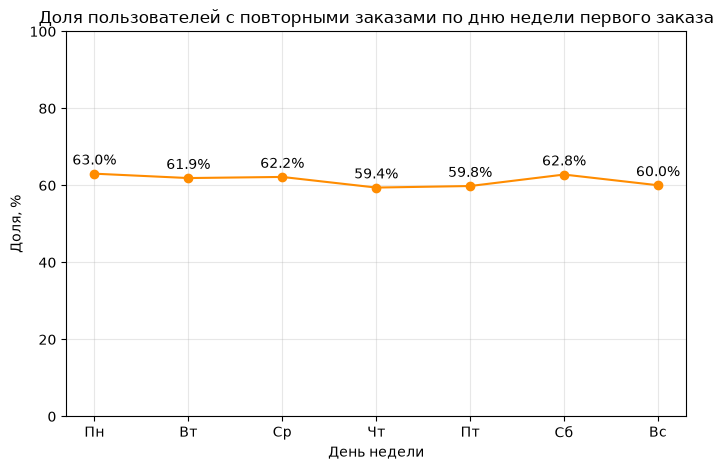

In [62]:
plt.figure(figsize=(8, 5))
plt.plot(weekday_stats.index, weekday_stats['repeat_share_pct'], marker='o', color='darkorange')

plt.title('Доля пользователей с повторными заказами по дню недели первого заказа')
plt.xlabel('День недели')
plt.ylabel('Доля, %')
plt.ylim(0, 100)

for i, v in enumerate(weekday_stats['repeat_share_pct']):
    plt.text(i, v + 1.5, f'{v:.1f}%', ha='center', va='bottom')

plt.grid(alpha=0.3)
plt.show()

День недели первой покупки слабо влияет на вероятность возврата. Доля вернувшихся составляет 59.4-63% во все дни, и явных "лучших" или "худших" дней нет. Для маркетинговых решений день первой покупки лучше не использовать как ключевой признак.

Изучим, как средний интервал между заказами влияет на удержание клиентов.

In [63]:
res = user_profile[user_profile['is_two']].groupby('is_five')['avg_days_between'].agg(['count', 'mean', 'median'])
res.index = ['2-4 заказа', '5+ заказов']
display(res)

,count,mean,median
2-4 заказа,7147,21.317884,9.000000
5+ заказов,6123,9.901352,8.117647


Среднее у двух групп различается более чем вдвое (21.3 vs 9.9 дня). Те, кто заказывает чаще, в среднем возвращаются заметно быстрее.

Типичный пользователь в обеих группах заказывает примерно раз в 8-9 дней.

Чем короче и стабильнее интервал между заказами, тем выше шанс, что пользователь станет постоянным (5+ заказов). Длинные паузы, то есть правый хвост в группе 2-4, характерны для тех, кто остаётся "нерегулярным" покупателем. У "постоянных" почти нет долгих пауз.

### 4.4. Корреляционный анализ количества покупок и признаков пользователя

In [64]:
user_profile.info()

<class 'pandas.DataFrame'>
Index: 21638 entries, 0 to 21853
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            21638 non-null  str           
 1   first_order_dt     21638 non-null  datetime64[us]
 2   last_order_dt      21638 non-null  datetime64[us]
 3   first_device       21638 non-null  str           
 4   first_region       21638 non-null  str           
 5   first_partner      21638 non-null  str           
 6   first_event_type   21638 non-null  str           
 7   total_orders       21638 non-null  int64         
 8   avg_revenue_rub    21638 non-null  float64       
 9   avg_tickets_count  21638 non-null  float64       
 10  avg_days_between   13305 non-null  float32       
 11  is_two             21638 non-null  bool          
 12  is_five            21638 non-null  bool          
 13  tickets_segment    21638 non-null  str           
dtypes: bool(2), datetime64

Рассчитаем коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов `total_orders`:

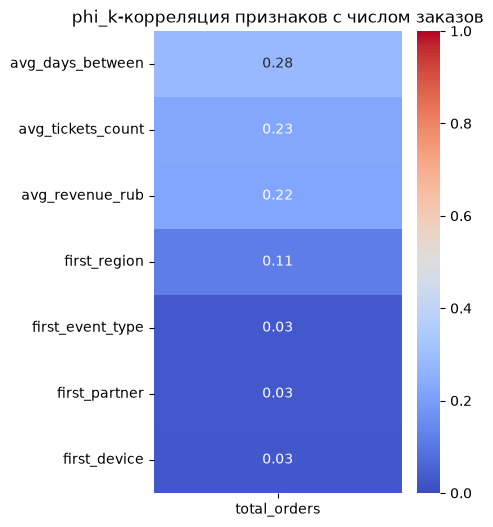

In [65]:
interval_cols = ['total_orders', 'avg_revenue_rub', 'avg_tickets_count', 'avg_days_between']

phik_with_orders = (
    user_profile
    .drop(columns=['user_id', 'first_order_dt', 'last_order_dt', 'is_two', 'is_five', 'tickets_segment'])
    .phik_matrix(interval_cols=interval_cols, njobs=1)[['total_orders']]
    .drop('total_orders')
    .sort_values(by='total_orders', ascending=False)
)

plt.figure(figsize=(4, 6))
sns.heatmap(phik_with_orders, annot=True, fmt='.2f', cmap='coolwarm', vmin=0, vmax=1)
plt.title('phi_k-корреляция признаков с числом заказов')
plt.show()

Больше всего с количеством заказов связаны три числовых признака:

- `avg_days_between` (0.28) — средний интервал между заказами. Это самая сильная связь, но она отчасти механическая: чем больше заказов, тем короче в среднем пауза между ними.
- `avg_tickets_count` (0.23) — среднее число билетов в заказе.
- `avg_revenue_rub` (0.22) — средняя выручка с заказа.

Связи в целом умеренные и слабые: максимум 0.28 по шкале от 0 до 1. Это значит, что ни один признак в одиночку не определяет число заказов. Поведение пользователя (как часто и на какую сумму он покупает) связано с количеством заказов заметнее, чем характеристики первого заказа (устройство, партнер, тип мероприятия).

## 5. Общие выводы и рекомендации

**Информация о данных:**
- Данные выгружены SQL-запросом из базы данных PostgreSQL `data-analyst-afisha`: `purchases`, `events`, `city` и `regions`.
- В SQL оставлены только устройства `mobile` и `desktop`, исключены "фильмы".
- Размер выгрузки: 290611 строк и 15 столбцов.
- Поле `days_since_prev`. Оно считается прямо в SQL как разница дат с предыдущим заказом пользователя. Для первого заказа (и единственного) значение пустое.
- Пропуски только в `days_since_prev` (7.6%).
- Для `service_name` искали значения '', '-', '—', 'unknown', 'неизвестно', 'нет данных', 'не указано', 'null', 'none', 'nan', 'n/a'. Ничего не нашли.
- Данные содержат информацию за период с 2024-06-01 по 2024-10-31.
- 5069 заказов (1.7%) были оформлены в `kzt`, остальные в `rub`. Выручка пересчитана по курсу на дату заказа из `final_tickets_tenge_df.csv` (курс указан за 100 тенге). Результат записан в столбец `revenue_rub`.
- Полнота курсов по датам не проверялась.
- Удалены заказы с `revenue_rub` выше 99-го перцентиля.
- Причина отрицательной выручки не выяснена, строки оставлены.
- Удалены пользователи выше 99-го перцентиля (больше 152 заказов на пользователя).
- Билеты в заказе. Максимум 57 (вероятно, групповые покупки), оставили без фильтрации.
- Итоговая выборка: 21638 пользователей.
- *Замечание*: `days_since_prev` посчитан в SQL до фильтрации по выручке. После удаления дорогих заказов он может не соответствовать фактическому предыдущему заказу.

Основные результаты анализа.

1. Выборка и распределение заказов

- В выборке 21638 пользователей. Половина сделала 1-2 заказа, 75% — не больше 5, среднее 6.5.
- Средняя выручка с заказа 518 руб., среднее число билетов 2.74, медианный интервал между заказами 8.3 дня.

2. Признаки первого заказа и возврат

- Связь слабая: доля вернувшихся в сегментах 56-64%.
- Чаще возвращаются пользователи, начавшие с театра (63.4%) и выставок (64%, но выборка мала), а также с desktop (63.8% против 60.8% у mobile).
- Реже возвращаются начавшие со спорта и елок (по 55.8%). Билетный оператор почти не влияет.
- Обе гипотезы не подтвердились: спорт не возвращается чаще концертов, а в крупных регионах доля возврата не выше.

3. Выручка и билеты

- Пользователи с одним заказом чаще имеют низкую среднюю выручку (до 100-200 руб.). Вернувшиеся чаще в диапазоне 300-900 руб.
- Больше всего возвращаются при среднем числе билетов от 2 до 3 (73.6%), меньше всего при 5 и более (18.8%).

4. Временные характеристики

- День недели первой покупки почти не влияет (59.4-63%).
- У пользователей с 5+ заказами интервал между покупками короче, в среднем 9.9 дня. У пользователей с 2-4 заказами 21,3 дня.

5. Корреляции с числом заказов

- Связи слабые, максимум 0.28.
- Заметнее связаны признаки поведения пользователя: средний интервал между заказами (0.28), среднее число билетов (0.23) и средняя выручка (0.22).
- Характеристики первого заказа связаны с числом заказов слабее.

**Общий вывод**

Около 62% пользователей Яндекс Афиши возвращаются на платформу. Характеристики первого заказа (тип мероприятия, устройство, регион, оператор) различают пользователей слабо: доля вернувшихся в сегментах 56-64%. Заметнее влияет поведение пользователя: состав заказа (число билетов, выручка) и частота покупок. Одной характеристикой, определяющей возврат, не выделяется ни один признак: корреляции слабые (до 0.28).

Самый заметный результат анализа: связь возврата с числом билетов немонотонна. Лучше всего возвращаются пользователи со средним числом билетов от 2 до 3 (73.6%), хуже всего пользователи с заказами на 5+ билетов (18.8%). Доли возврата могут быть занижены у пользователей, впервые купивших в сентябре и октябре: у них было мало времени на повторную покупку. Из-за того, что `days_since_prev` посчитан до фильтрации по выручке, часть интервалов может быть неточной. Нерешенными остаются максимум в 10181 заказ у одного пользователя и отрицательная выручка.

**Рекомендации**

- Пользователи с 2-3 билетами в заказе. Это самый большой сегмент, 73.6% возвращаются. Их стоит удерживать напоминаниями и персональными подборками.
- Начавшие с театра (63.4%). Театр можно использовать как точку входа для привлечения.
- Пользователи с 5+ заказами и коротким интервалом (в среднем 9.9 дня): программа лояльности и ранний доступ к продаже.